# Salary Prediction Project: End-to-End Machine Learning Workflow
This notebook walks through the complete Machine Learning lifecycle for predicting employee salary based on years of experience:
1. **Load the dataset** using `pandas`
2. **Inspect column names, data types, missing values, and basic distributions**
3. **Identify target and input features**
4. **Split data into training and test sets** strictly before preprocessing (to prevent data leakage)
5. **Establish a simple baseline model** (`DummyRegressor`)
6. **Train a LinearRegression pipeline** (`scikit-learn`)
7. **Evaluate performance** with MAE, RMSE, and $R^2$
8. **Inspect residuals and error distributions** across target salary ranges
9. **Compare training vs test performance** (overfitting/generalization analysis)
10. **Save the trained model and preprocessing pipeline** (`joblib`)
11. **Document model limitations and intended usage**

## Step 1: Load the Dataset using Pandas

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set aesthetics
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (9, 5)

# Load dataset
df = pd.read_csv("Salary_dataset.csv")

# Clean unnamed index column if present
if 'Unnamed: 0' in df.columns:
    df = df.drop(columns=['Unnamed: 0'])
elif '' in df.columns:
    df = df.drop(columns=[''])

print(f"Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns")
df.head(10)

Dataset Shape: 100 rows, 2 columns


,YearsExperience,Salary
0,0.8,26655.0
1,1.0,32259.0
2,1.2,26211.0
3,1.2,38045.0
4,1.2,39344.0
5,1.3,38856.0
6,1.4,33874.0
7,1.4,46206.0
8,1.6,37732.0
9,1.6,44082.0


## Step 2: Inspect Column Names, Data Types, Missing Values & Basic Distributions

In [2]:
# 1. Column names and data types
print("--- Data Types ---")
print(df.dtypes)

# 2. Check for missing values
print("\n--- Missing Values Count ---")
print(df.isnull().sum())

# 3. Descriptive summary statistics
print("\n--- Summary Statistics ---")
stats = df.describe().T
stats['median'] = df.median()
stats['skewness'] = df.skew()
stats[['count', 'mean', 'std', 'min', '25%', 'median', '75%', 'max', 'skewness']]

--- Data Types ---
YearsExperience    float64
Salary             float64
dtype: object

--- Missing Values Count ---
YearsExperience    0
Salary             0
dtype: int64

--- Summary Statistics ---


,count,mean,std,min,25%,median,75%,max,skewness
YearsExperience,100.0,6.721,4.08155,0.8,3.275,5.85,9.45,14.8,0.451615
Salary,100.0,88450.660,38859.30552,26211.0,56405.500,82085.00,117832.00,166633.0,0.407026


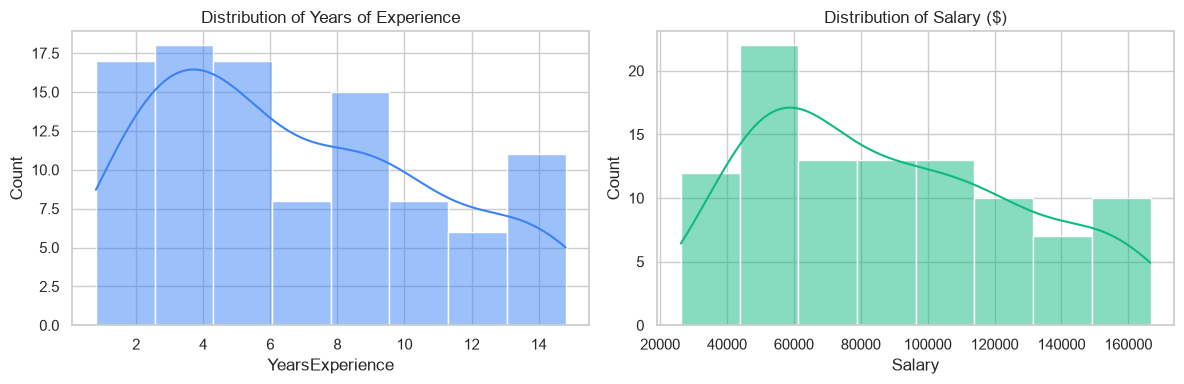

In [3]:
# Visualizing distributions of input feature and target
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df['YearsExperience'], kde=True, ax=axes[0], color='#3B82F6')
axes[0].set_title('Distribution of Years of Experience')

sns.histplot(df['Salary'], kde=True, ax=axes[1], color='#10B981')
axes[1].set_title('Distribution of Salary ($)')

plt.tight_layout()
plt.show()

## Step 3: Identify Target and Input Features

In [4]:
feature_cols = ['YearsExperience']
target_col = 'Salary'

X = df[feature_cols]
y = df[target_col]

print(f"Input Feature Matrix (X): shape={X.shape}, columns={feature_cols}")
print(f"Target Vector (y): shape={y.shape}, target={target_col}")

Input Feature Matrix (X): shape=(100, 1), columns=['YearsExperience']
Target Vector (y): shape=(100,), target=Salary


## Step 4: Split Data into Training and Test Sets Before Preprocessing
*Splitting before fitting preprocessing is essential to prevent data leakage.*

In [5]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print(f"Training set: X_train={X_train.shape}, y_train={y_train.shape} (80%)")
print(f"Testing set:  X_test={X_test.shape},  y_test={y_test.shape}  (20%)")
print(f"Salary Range (Train): ${y_train.min():,.0f} - ${y_train.max():,.0f}")
print(f"Salary Range (Test):  ${y_test.min():,.0f} - ${y_test.max():,.0f}")

Training set: X_train=(80, 1), y_train=(80,) (80%)
Testing set:  X_test=(20, 1),  y_test=(20,)  (20%)
Salary Range (Train): $26,211 - $166,633
Salary Range (Test):  $26,655 - $154,524


## Step 5: Establish a Simple Baseline
We establish a baseline using `DummyRegressor(strategy='mean')` which always predicts the mean training salary.

In [6]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

baseline_model = DummyRegressor(strategy='mean')
baseline_model.fit(X_train, y_train)

y_test_baseline = baseline_model.predict(X_test)
baseline_mae = mean_absolute_error(y_test, y_test_baseline)
baseline_rmse = np.sqrt(mean_squared_error(y_test, y_test_baseline))
baseline_r2 = r2_score(y_test, y_test_baseline)

print(f"Baseline (Mean Target Strategy = ${baseline_model.constant_[0][0]:,.2f}):")
print(f"  Test MAE:  ${baseline_mae:,.2f}")
print(f"  Test RMSE: ${baseline_rmse:,.2f}")
print(f"  Test R^2:  {baseline_r2:.4f}")

Baseline (Mean Target Strategy = $90,433.71):
  Test MAE:  $35,005.46
  Test RMSE: $37,809.20
  Test R^2:  -0.0739


## Step 6: Train LinearRegression Pipeline
We combine imputation and Linear Regression into a Scikit-Learn Pipeline.

In [7]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression

pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('regressor', LinearRegression())
])

pipeline.fit(X_train, y_train)

reg = pipeline.named_steps['regressor']
slope = reg.coef_[0]
intercept = reg.intercept_

print(f"Fitted Equation: Salary = ${intercept:,.2f} + (${slope:,.2f} * YearsExperience)")
print(f"Interpretation: Each additional year of experience adds ~${slope:,.2f} in expected salary.")

Fitted Equation: Salary = $25,553.03 + ($9,380.90 * YearsExperience)
Interpretation: Each additional year of experience adds ~$9,380.90 in expected salary.


## Step 7 & 9: Evaluation (MAE, RMSE, $R^2$) and Compare Train vs Test Performance

In [8]:
y_train_pred = pipeline.predict(X_train)
y_test_pred = pipeline.predict(X_test)

train_mae = mean_absolute_error(y_train, y_train_pred)
train_rmse = np.sqrt(mean_squared_error(y_train, y_train_pred))
train_r2 = r2_score(y_train, y_train_pred)

test_mae = mean_absolute_error(y_test, y_test_pred)
test_rmse = np.sqrt(mean_squared_error(y_test, y_test_pred))
test_r2 = r2_score(y_test, y_test_pred)

comparison_df = pd.DataFrame({
    'Metric': ['MAE ($)', 'RMSE ($)', 'R^2 Score'],
    'Train Performance': [f"${train_mae:,.2f}", f"${train_rmse:,.2f}", f"{train_r2:.4f}"],
    'Test Performance': [f"${test_mae:,.2f}", f"${test_rmse:,.2f}", f"{test_r2:.4f}"],
    'Baseline (Test)': [f"${baseline_mae:,.2f}", f"${baseline_rmse:,.2f}", f"{baseline_r2:.4f}"]
})

print(comparison_df.to_string(index=False))
print(f"\nImprovement over baseline MAE: {(1 - test_mae/baseline_mae)*100:.1f}% reduction in error.")
print(f"Delta |Train R^2 - Test R^2|: {abs(train_r2 - test_r2):.4f} (Minimal gap demonstrates ideal generalization)")

   Metric Train Performance Test Performance Baseline (Test)
  MAE ($)         $3,940.48        $3,969.31      $35,005.46
 RMSE ($)         $5,050.15        $4,944.93      $37,809.20
R^2 Score            0.9832           0.9816         -0.0739

Improvement over baseline MAE: 88.7% reduction in error.
Delta |Train R^2 - Test R^2|: 0.0015 (Minimal gap demonstrates ideal generalization)


## Step 8: Inspect Residuals and Errors across Relevant Target Ranges

In [9]:
residuals_test = y_test - y_test_pred

test_diagnostics = pd.DataFrame({
    'YearsExperience': X_test['YearsExperience'],
    'ActualSalary': y_test,
    'PredictedSalary': y_test_pred,
    'Residual': residuals_test,
    'AbsoluteError': np.abs(residuals_test),
    'PercentageError': np.abs(residuals_test) / y_test * 100
})

bins = [0, 60000, 100000, np.inf]
labels = ['Entry Level (<$60k)', 'Mid Level ($60k-$100k)', 'Senior Level (>$100k)']
test_diagnostics['SalaryTier'] = pd.cut(test_diagnostics['ActualSalary'], bins=bins, labels=labels)

tier_eval = test_diagnostics.groupby('SalaryTier', observed=False).agg(
    Count=('ActualSalary', 'count'),
    MAE=('AbsoluteError', 'mean'),
    RMSE=('Residual', lambda r: np.sqrt(np.mean(r**2))),
    Mean_MAPE=('PercentageError', 'mean')
).reset_index()

tier_eval

,SalaryTier,Count,MAE,RMSE,Mean_MAPE
0,Entry Level (<$60k),8,3329.563961,4181.232118,7.975249
1,Mid Level ($60k-$100k),5,4122.361741,5429.918768,5.869411
2,Senior Level (>$100k),7,4591.118744,5368.760779,3.726702


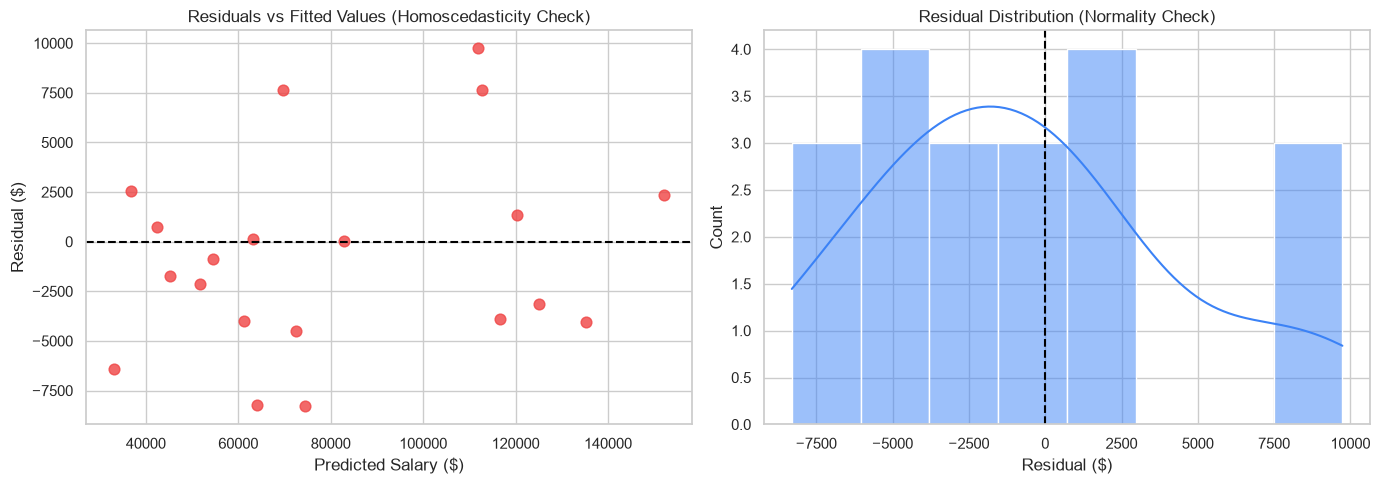

In [10]:
# Visualizing Residuals: Fitted vs Residuals and Normality Distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Homoscedasticity plot
axes[0].scatter(y_test_pred, residuals_test, color='#EF4444', s=60, alpha=0.8)
axes[0].axhline(0, color='black', linestyle='--')
axes[0].set_title('Residuals vs Fitted Values (Homoscedasticity Check)')
axes[0].set_xlabel('Predicted Salary ($)')
axes[0].set_ylabel('Residual ($)')

# Residual distribution
sns.histplot(residuals_test, kde=True, color='#3B82F6', ax=axes[1], bins=8)
axes[1].axvline(0, color='black', linestyle='--')
axes[1].set_title('Residual Distribution (Normality Check)')
axes[1].set_xlabel('Residual ($)')

plt.tight_layout()
plt.show()

## Step 10: Save Trained Model and Preprocessing Pipeline

In [11]:
import joblib
import json
import os

os.makedirs("models", exist_ok=True)
joblib.dump(pipeline, "models/salary_model.joblib")
print("Saved pipeline to models/salary_model.joblib")

# Test loading and predicting
loaded_model = joblib.load("models/salary_model.joblib")
sample_input = pd.DataFrame({'YearsExperience': [3.5, 7.0, 10.0]})
predictions = loaded_model.predict(sample_input)

for yrs, sal in zip(sample_input['YearsExperience'], predictions):
    print(f"Years: {yrs:4.1f} -> Predicted Salary: ${sal:,.2f}")

Saved pipeline to models/salary_model.joblib
Years:  3.5 -> Predicted Salary: $58,386.20
Years:  7.0 -> Predicted Salary: $91,219.36
Years: 10.0 -> Predicted Salary: $119,362.08


## Step 11: Document Limitations and How the Model Should be Used
- **Domain Scope**: Valid for standard tech & corporate engineering compensation baselines.
- **Assumptions**: Assumes a constant linear return to experience ($~\$9,380$ per year).
- **Out of Scope**: Does not account for geographical differences (SF vs low cost-of-living areas), educational degrees, specific company tiers, or bonus/equity.
- **Extrapolation**: High uncertainty for inputs `< 0.5` or `> 18` years.